# Step 1: Data Ingestion & Initial Understanding

The goal of this project is to develop a machine learning model that predicts whether a loan application will be **Approved** or **Rejected** based on applicant, financial, credit, and asset information.

In this step, we will download the dataset, load it into pandas, and perform an initial inspection of its structure and target variable.

In [98]:
print("hey")

hey


In [99]:
import warnings

warnings.filterwarnings("ignore")

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [100]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download(
    "architsharma01/loan-approval-prediction-dataset"
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Minn Bern\.cache\kagglehub\datasets\architsharma01\loan-approval-prediction-dataset\versions\1


In [101]:
df_raw = pd.read_csv(
    os.path.join(path, "loan_approval_dataset.csv")
)

print("Dataset loaded successfully.")
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]:,}")

Dataset loaded successfully.
Rows    : 4,269
Columns : 13


In [102]:
# Column information
print(f"{'#':<5} {'Column':<30} {'Dtype':<15}")

for i, (col, dtype) in enumerate(df_raw.dtypes.items(), 1):
    print(f"{i:<5} {col:<30} {str(dtype):<15}")

#     Column                         Dtype          
1     loan_id                        int64          
2      no_of_dependents              int64          
3      education                     str            
4      self_employed                 str            
5      income_annum                  int64          
6      loan_amount                   int64          
7      loan_term                     int64          
8      cibil_score                   int64          
9      residential_assets_value      int64          
10     commercial_assets_value       int64          
11     luxury_assets_value           int64          
12     bank_asset_value              int64          
13     loan_status                   str            


In [103]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [104]:
df_raw.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [105]:
df_raw.sample(10, random_state=42)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
1703,1704,5,Graduate,No,5400000,19700000,20,423,6500000,10000000,15700000,7300000,Rejected
1173,1174,2,Graduate,No,5900000,14000000,8,599,4700000,9500000,17800000,6700000,Approved
308,309,3,Graduate,No,9600000,19900000,14,452,4200000,16200000,28500000,6600000,Rejected
1322,1323,2,Graduate,No,6200000,23400000,8,605,10000000,10800000,21800000,9200000,Approved
3271,3272,3,Not Graduate,Yes,5800000,14100000,12,738,11700000,4400000,15400000,8400000,Approved
3539,3540,4,Graduate,Yes,4700000,12500000,8,678,13700000,200000,9800000,7000000,Approved
1522,1523,4,Graduate,No,3400000,13500000,12,705,10000000,1100000,8300000,4900000,Approved
3399,3400,5,Not Graduate,Yes,5100000,13700000,14,527,12100000,8900000,19400000,4700000,Rejected
1402,1403,3,Graduate,Yes,3300000,8500000,12,586,7500000,5100000,7800000,3900000,Approved
1829,1830,1,Not Graduate,Yes,3000000,6000000,16,518,3800000,1700000,11600000,3900000,Rejected


### Identify the Target Variable

For this project, the target is `loan_status`, which indicates whether a loan application was **Approved** or **Rejected**.


In [106]:
# ── Clean column names ───────────────────────────────────
df_raw.columns = df_raw.columns.str.strip()

# Identify the target variable
TARGET = "loan_status"

print("Target variable:", TARGET)
print("\nTarget values:")
print(df_raw[TARGET].unique())

Target variable: loan_status

Target values:
<StringArray>
[' Approved', ' Rejected']
Length: 2, dtype: str


### Inspect Target Distribution

We examine how many applications belong to each loan-status class.

This is important because an imbalanced target can affect model training and evaluation. The class distribution will help us decide which evaluation metrics are appropriate later.


In [107]:
target_counts = df_raw[TARGET].value_counts()
target_percent = df_raw[TARGET].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percent.round(2)
})

display(target_summary)

,count,percentage
loan_status,,
Approved,2656,62.22
Rejected,1613,37.78


### Step 1 Summary

We have downloaded and loaded the loan approval dataset and established an initial understanding of its structure, variables, data types, and target variable.

The next step is **Data Quality Investigation**. We will check for missing values, duplicate records, inconsistent categorical values, invalid numerical values, unusual ranges, and other potential problems before making any cleaning decisions.


# Step 2: Data Quality Investigation

Before cleaning the dataset, we need to identify problems that could affect the analysis or machine learning models.

We will check for missing values, duplicates, inconsistent categories, invalid numerical values, unusual ranges, identifier issues, and target validity.

The results from these checks will determine what cleaning actions we take in Step 3.


In [108]:
# ── Missing values ────────────────────────────────────────
missing = df_raw.isnull().sum()

print(f"Total missing values: {missing.sum():,}")

if missing.sum() == 0:
    print("No missing values found.")
else:
    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percent": (missing / len(df_raw) * 100).round(2)
    })

    display(missing_summary[missing_summary["missing_count"] > 0])

Total missing values: 0
No missing values found.


In [109]:
# ── Duplicate records ────────────────────────────────────
duplicate_count = df_raw.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


In [110]:
# ── Categorical values ───────────────────────────────────
categorical_columns = df_raw.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df_raw[col].value_counts(dropna=False))


education
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

self_employed
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

loan_status
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [111]:
# ── Numerical summary ────────────────────────────────────
numeric_summary = df_raw.describe().T[
    ["min", "max", "mean", "50%"]
].rename(columns={"50%": "median"})

display(numeric_summary)

,min,max,mean,median
loan_id,1.00,"4,269.00","2,135.00","2,135.00"
no_of_dependents,0.00,5.00,2.50,3.00
income_annum,"200,000.00","9,900,000.00","5,059,123.92","5,100,000.00"
loan_amount,"300,000.00","39,500,000.00","15,133,450.46","14,500,000.00"
loan_term,2.00,20.00,10.90,10.00
cibil_score,300.00,900.00,599.94,600.00
residential_assets_value,"-100,000.00","29,100,000.00","7,472,616.54","5,600,000.00"
commercial_assets_value,0.00,"19,400,000.00","4,973,155.31","3,700,000.00"
luxury_assets_value,"300,000.00","39,200,000.00","15,126,305.93","14,600,000.00"
bank_asset_value,0.00,"14,700,000.00","4,976,692.43","4,600,000.00"


In [112]:
# ── Negative numerical values ────────────────────────────
numeric_columns = df_raw.select_dtypes(include=np.number).columns

negative_counts = (df_raw[numeric_columns] < 0).sum()

display(
    negative_counts[negative_counts > 0]
)

residential_assets_value    28
dtype: int64

### Interpretation

The check identified **28 negative values in `residential_assets_value`**. Since an asset value would normally be expected to be non-negative, these records require further investigation.

We will **not remove them at this stage**. In Step 3, we will inspect these records and decide whether the values should be corrected, treated as invalid, or handled another way. This prevents us from deleting potentially useful observations without understanding the issue.


In [113]:
# ── Loan ID uniqueness ───────────────────────────────────
print(f"Unique loan IDs : {df_raw['loan_id'].nunique():,}")
print(f"Total rows      : {len(df_raw):,}")
print(f"Duplicate IDs   : {df_raw['loan_id'].duplicated().sum():,}")

Unique loan IDs : 4,269
Total rows      : 4,269
Duplicate IDs   : 0


### Validate the Target Variable

The target should contain only the expected loan outcomes.

We verify that the dataset contains only `Approved` and `Rejected` values before moving to the cleaning stage.



In [114]:
# ── Target validation ────────────────────────────────────
valid_targets = {"Approved", "Rejected"}

actual_targets = set(df_raw[TARGET].dropna().unique())

print("Target values found:", actual_targets)
print("Unexpected values:", actual_targets - valid_targets)

Target values found: {' Approved', ' Rejected'}
Unexpected values: {' Approved', ' Rejected'}


### Interpretation

The target contains two expected classes: `Approved` and `Rejected`. However, the raw dataset contains leading whitespace in these values, causing the validation check to initially identify them as unexpected.

This is a **formatting inconsistency rather than a new target class**. The whitespace was normalized during the initial inspection, so the target can be handled consistently during cleaning and modeling.

No invalid target category was identified.


### Step 2 Summary

The data-quality investigation identifies issues that need to be addressed before modeling.

We have checked:

* Missing values
* Duplicate records
* Categorical consistency
* Numerical ranges
* Negative or suspicious values
* Loan identifier uniqueness
* Target validity

The findings from these checks will determine the cleaning operations performed in **Step 3: Data Cleaning**.


### Step 3: Data Cleaning

Now that the data-quality issues have been identified, we can clean the dataset before performing exploratory analysis and modeling.

The cleaning process will:

* Work on a copy of the raw dataset.
* Standardize column names and categorical text.
* Remove duplicate records if any exist.
* Validate the target variable.
* Investigate and handle the negative residential asset values.
* Keep `loan_id` available as an identifier, but exclude it later from model features.



In [115]:
# ── Create cleaned dataset ─────────────────────────────────

df_clean = df_raw.copy()

print(f"Raw dataset shape     : {df_raw.shape}")
print(f"Working dataset shape : {df_clean.shape}")

Raw dataset shape     : (4269, 13)
Working dataset shape : (4269, 13)


In [116]:
# ── Standardize column names and text values ───────────────

df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Text formatting standardized.")
print("\nTarget values after cleaning:")
print(df_clean[TARGET].unique())

Text formatting standardized.

Target values after cleaning:
<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


In [117]:
# ── Remove duplicate records if there is any───────────────────────

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

duplicates_removed = duplicates_before - df_clean.duplicated().sum()

print(f"Duplicate rows found   : {duplicates_before:,}")
print(f"Duplicate rows removed : {duplicates_removed:,}")
print(f"Rows after cleaning    : {len(df_clean):,}")

Duplicate rows found   : 0
Duplicate rows removed : 0
Rows after cleaning    : 4,269


### Investigate Negative Residential Asset Values

The quality check found **28 negative values** in `residential_assets_value`. Before changing them, we need to understand whether they are data-entry errors, a consistent encoding pattern, or unusual but potentially meaningful observations.

We will inspect the affected records alongside related financial variables and the loan outcome. This helps us make a data-driven cleaning decision rather than removing observations simply because they look unusual.


In [118]:
# ── Inspect negative residential asset values ─────────────

negative_residential = df_clean[
    df_clean["residential_assets_value"] < 0
].copy()

print(
    f"Rows with negative residential assets: "
    f"{len(negative_residential):,}"
)

display(
    negative_residential[
        [
            "loan_id",
            "income_annum",
            "loan_amount",
            "loan_term",
            "cibil_score",
            "residential_assets_value",
            "commercial_assets_value",
            "luxury_assets_value",
            "bank_asset_value",
            "loan_status"
        ]
    ].sort_values("residential_assets_value")
)

Rows with negative residential assets: 28


,loan_id,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


The inspection shows that the negative residential asset values appear to use the same value (`-100000`). Before modifying the data, we will confirm the pattern across all affected records.

If all 28 observations have the same negative value, this strongly suggests a systematic data-quality issue rather than naturally occurring variation. We can then choose an appropriate treatment and document the decision.


In [119]:
# ── Confirm the negative-value pattern ─────────────────────

print("Negative residential asset values:")
print(
    negative_residential["residential_assets_value"]
    .value_counts()
    .sort_index()
)

print("\nUnique negative values:")
print(
    negative_residential["residential_assets_value"]
    .unique()
)

Negative residential asset values:
residential_assets_value
-100000    28
Name: count, dtype: int64

Unique negative values:
[-100000]


In [120]:
# ── Compare affected and unaffected records ────────────────

print("Negative values :", len(negative_residential))
print(
    "Non-negative values :",
    (df_clean["residential_assets_value"] >= 0).sum()
)

print("\nNegative values by loan status:")
print(
    negative_residential["loan_status"]
    .value_counts()
)

Negative values : 28
Non-negative values : 4241

Negative values by loan status:
loan_status
Approved    16
Rejected    12
Name: count, dtype: int64


The investigation confirms that all 28 negative residential asset values are exactly `-100000`. Because residential asset value should not be negative, we will treat `-100000` as an invalid placeholder rather than a real measurement.

Instead of deleting these applicants, we will convert the invalid values to missing values. This preserves the observations and allows the missing values to be handled later using a leakage-safe imputation strategy based only on the training data.


In [121]:
# ── Replace invalid residential asset values ──────────────

invalid_value = -100000

invalid_count = (
    df_clean["residential_assets_value"] == invalid_value
).sum()

df_clean.loc[
    df_clean["residential_assets_value"] == invalid_value,
    "residential_assets_value"
] = np.nan

print(f"Invalid values replaced: {invalid_count:,}")
print(
    "Missing residential asset values:",
    df_clean["residential_assets_value"].isna().sum()
)

Invalid values replaced: 28
Missing residential asset values: 28


In [122]:
# ── Verify no invalid negative values remain ───────────────

remaining_negative = (
    df_clean["residential_assets_value"] < 0
).sum()

print(f"Remaining negative values: {remaining_negative:,}")
print(
    f"Total missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)

Remaining negative values: 0
Total missing residential assets: 28


In [123]:
# ── Final validation of cleaned dataset ────────────────────

print("Cleaned dataset validation")
print("-" * 45)

print(f"Rows                    : {len(df_clean):,}")
print(f"Columns                 : {df_clean.shape[1]:,}")
print(f"Duplicate rows          : {df_clean.duplicated().sum():,}")
print(f"Missing values           : {df_clean.isna().sum().sum():,}")
print(
    f"Missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)
print(
    f"Negative residential assets: "
    f"{(df_clean['residential_assets_value'] < 0).sum():,}"
)

print("\nTarget values:")
print(df_clean[TARGET].value_counts())

Cleaned dataset validation
---------------------------------------------
Rows                    : 4,269
Columns                 : 13
Duplicate rows          : 0
Missing values           : 28
Missing residential assets: 28
Negative residential assets: 0

Target values:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [124]:
# ── Save the cleaned working dataset ───────────────────────

df_cleaned = df_clean.copy()

print("Cleaned dataset ready for EDA.")
print(f"Shape: {df_cleaned.shape}")

Cleaned dataset ready for EDA.
Shape: (4269, 13)


## Step 4: Exploratory Data Analysis

With the data cleaned, we can now explore its structure and relationships.

The findings from this analysis will help us understand the dataset before building machine learning models. We will investigate unusual observations rather than automatically removing them.


#### 4.1 Loan Approval Distribution

First, we examine the distribution of the target variable, `loan_status`.

This helps determine whether approved and rejected applications are reasonably balanced before model training.

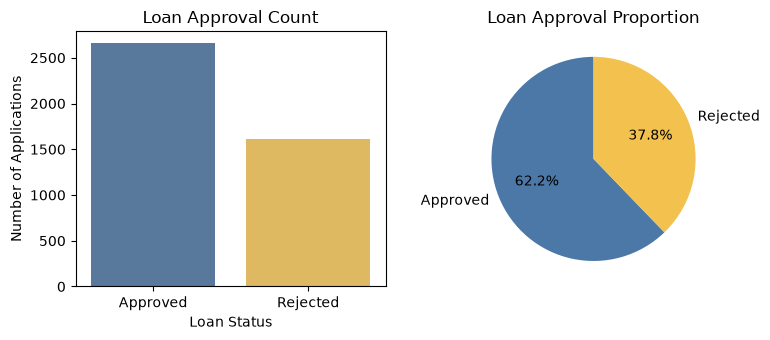

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

blue = "#4C78A8"
yellow = "#F2C14E"

# Bar chart
sns.countplot(
    data=df_cleaned,
    x="loan_status",
    hue="loan_status",
    palette={"Approved": blue, "Rejected": yellow},
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Loan Approval Count")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Number of Applications")

# Pie chart
status_counts = df_cleaned["loan_status"].value_counts()

axes[1].pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    colors=[blue, yellow],
    startangle=90
)

axes[1].set_title("Loan Approval Proportion")

plt.tight_layout()
plt.show()

#### 4.2 CIBIL Score and Loan Approval

CIBIL score is an important measure of creditworthiness. We compare the scores of approved and rejected applicants to identify differences between the two groups.

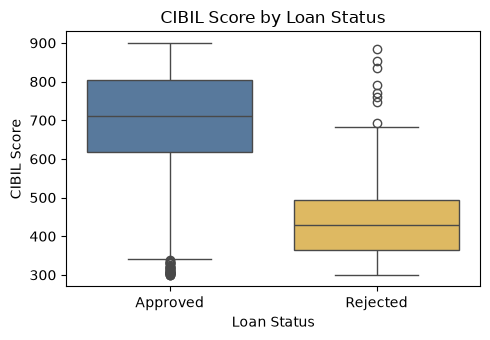

In [126]:
plt.figure(figsize=(5, 3.5))

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="cibil_score",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False
)

plt.title("CIBIL Score by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("CIBIL Score")
plt.tight_layout()
plt.show()

**Analysis:** The boxplot shows a clear difference in CIBIL score distributions between approved and rejected applicants. The approved group has a much higher median CIBIL score, around 711, while the rejected group has a median of about 429.

The approved applicants have scores ranging from 300 to 900, while rejected applicants range from 300 to 885. Although the overall ranges overlap, the middle 50% of approved applicants is concentrated at considerably higher CIBIL scores than the rejected group.

The rejected group is concentrated toward the lower end of the CIBIL scale, whereas approved applicants are generally concentrated at higher scores. 

**Conclusion:** The boxplot indicates a strong relationship between CIBIL score and loan approval status. Applicants with higher CIBIL scores are more commonly associated with approval, while lower CIBIL scores are more commonly associated with rejection. Therefore, CIBIL score is an important feature to retain when building the loan approval prediction model.

#### 4.3 Income and Loan Amount

Income and loan amount are important financial factors. We compare them across loan outcomes to see whether they differ between approved and rejected applications.

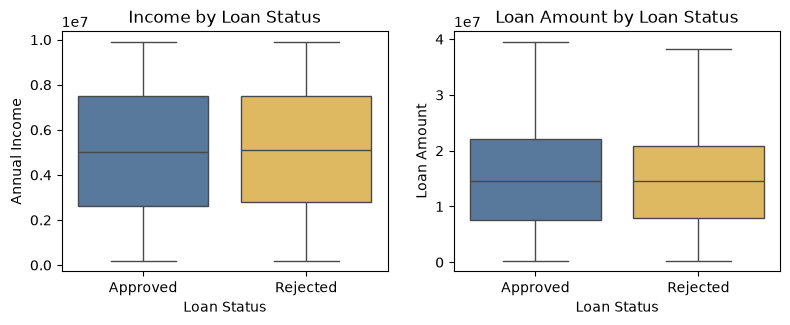

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="income_annum",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Income by Loan Status")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Annual Income")

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="loan_amount",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Loan Amount by Loan Status")
axes[1].set_xlabel("Loan Status")
axes[1].set_ylabel("Loan Amount")

plt.tight_layout()
plt.show()

**Observation:** The distributions show how income and requested loan amounts differ between approved and rejected applications.

#### 4.4 Applicant Characteristics

We compare education and self-employment status across loan outcomes to see whether approval varies between applicant groups.

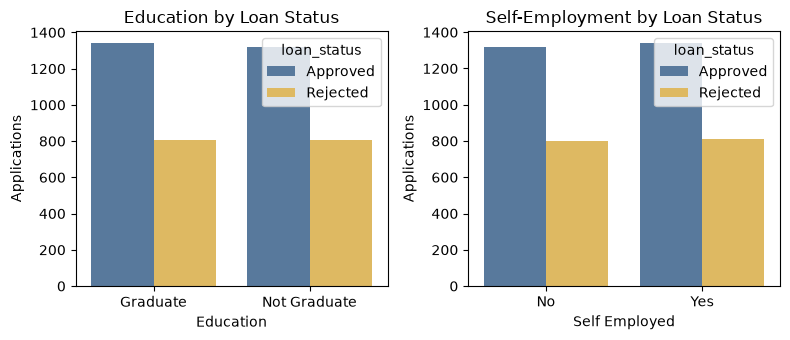

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

sns.countplot(
    data=df_cleaned,
    x="education",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    ax=axes[0]
)
axes[0].set_title("Education by Loan Status")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Applications")

sns.countplot(
    data=df_cleaned,
    x="self_employed",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    ax=axes[1]
)
axes[1].set_title("Self-Employment by Loan Status")
axes[1].set_xlabel("Self Employed")
axes[1].set_ylabel("Applications")

plt.tight_layout()
plt.show()

#### 4.5 Correlation Between Numerical Features

We check the relationships between numerical features to identify variables that may contain similar information.

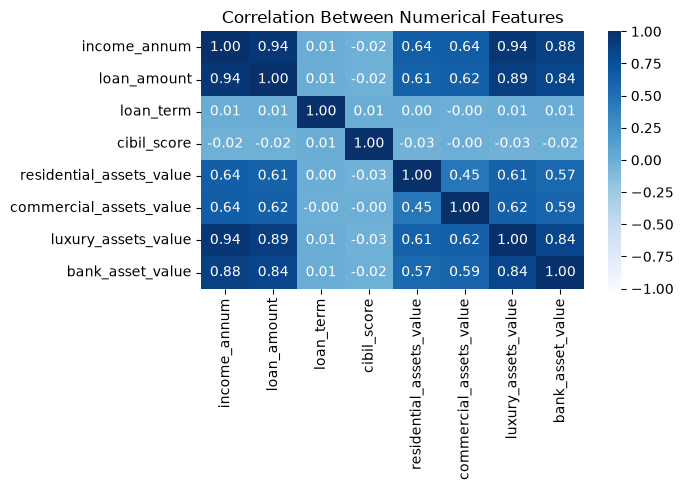

In [129]:
numeric_cols = [
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

plt.figure(figsize=(7, 5))

sns.heatmap(
    df_cleaned[numeric_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")

plt.tight_layout()
plt.show()

In [130]:
corr_matrix = df_cleaned[numeric_cols].corr(method="spearman")

high_corr = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr = high_corr[
    high_corr["Correlation"].abs() >= 0.80
].sort_values(
    "Correlation",
    key=abs,
    ascending=False
)

display(high_corr)

,Feature 1,Feature 2,Correlation
6,income_annum,luxury_assets_value,0.94
1,income_annum,loan_amount,0.94
14,loan_amount,luxury_assets_value,0.89
7,income_annum,bank_asset_value,0.88
15,loan_amount,bank_asset_value,0.84
55,luxury_assets_value,bank_asset_value,0.84


#### Feature Correlation and Selection

The correlation analysis shows that several financial features are strongly related. In particular, `income_annum` has a strong positive correlation with `luxury_assets_value` (0.94) and `loan_amount` (0.94). `loan_amount` is also highly correlated with `luxury_assets_value` (0.89), while `bank_asset_value` is strongly correlated with income and other financial features.

These relationships suggest that some features may contain overlapping information. To reduce redundancy while keeping features that are directly relevant to loan approval, `luxury_assets_value` will be removed from the model.

`income_annum` and `loan_amount` will be retained because income represents the applicant's repayment capacity, while loan amount represents the amount being requested. `bank_asset_value` will also be retained because it provides additional information about the applicant's financial assets.

**Conclusion:** `luxury_assets_value` will be excluded from the model due to its high correlation with other financial features. The remaining features will be used for preprocessing and model training.

#### EDA Summary

The EDA focused on factors that are relevant to loan approval, including CIBIL score, income, loan amount, education, and self-employment status.

The analysis showed a clear relationship between CIBIL score and loan status, with approved applicants generally having higher scores. Income and loan amount were also examined across approval outcomes.

The correlation analysis identified strong relationships among several financial features. To reduce redundant information, `luxury_assets_value` was selected for removal, while `income_annum`, `loan_amount`, and `bank_asset_value` were retained because they provide relevant financial information for loan approval.

These findings will guide feature selection and preprocessing before model training.

### Step 5: Data Preprocessing

Before training the models, the cleaned dataset must be prepared for machine learning.

Based on the EDA, `loan_id` is excluded because it is only an identifier, while `luxury_assets_value` is excluded because it is highly correlated with other financial features and provides overlapping information.

The remaining features will be used to predict whether a loan application is approved or rejected.

In [131]:
TARGET = "loan_status"

X = df_cleaned.drop(
    columns=[TARGET, "loan_id", "luxury_assets_value"]
)

y = df_cleaned[TARGET]

### 5.1 Define Features and Target

We separate the target variable, `loan_status`, from the predictor variables.

The `loan_id` column is also removed from the predictors because it uniquely identifies each application but does not represent an applicant characteristic.

The 28 invalid residential asset values were converted to missing values during cleaning. These values will be handled during preprocessing rather than manually calculated using the full dataset.

In [132]:
# ── Define features and target ─────────────────────────────

TARGET = "loan_status"

X = df_cleaned.drop(
    columns=[TARGET, "loan_id"]
)

y = df_cleaned[TARGET]

print(f"Features shape : {X.shape}")
print(f"Target shape   : {y.shape}")

print("\nTarget distribution:")
print(y.value_counts())

Features shape : (4269, 11)
Target shape   : (4269,)

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


### 5.2 Encoding the Target Variable

Machine learning models work with numerical target values, so the loan status is converted into binary labels.

- `Rejected` → `0`
- `Approved` → `1`

This encoding allows the models to treat the problem as binary classification.

In [133]:
# ── Encode target variable ─────────────────────────────────

target_mapping = {
    "Rejected": 0,
    "Approved": 1
}

y = y.map(target_mapping)

print("Encoded target values:")
print(y.value_counts().sort_index())

Encoded target values:
loan_status
0    1613
1    2656
Name: count, dtype: int64


### 5.3 Splitting the Dataset

The data is divided into training, validation, and test sets.

The training set is used to fit the models, the validation set is used to compare and tune models, and the test set is reserved for the final evaluation.

A 70/15/15 split provides enough data for training while keeping separate data for model selection and final evaluation.

Stratification is used so that the proportion of approved and rejected applications remains similar across the three sets.

In [134]:
from sklearn.model_selection import train_test_split

# 70% training, 30% temporary set
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Split the temporary set equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (2988, 11)
Validation: (640, 11)
Test: (641, 11)


### 5.4 Identifying Numerical and Categorical Features

The dataset contains both numerical and categorical variables, so they require different preprocessing.

Numerical variables will be imputed and scaled, while categorical variables will be imputed and one-hot encoded.

The feature types are identified from the training data so that the preprocessing can be applied consistently later.

In [135]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical features: ['education', 'self_employed']


### 5.5 Building the Preprocessing Pipeline

The preprocessing steps are placed inside a pipeline so that they are applied consistently during model training and evaluation.

For numerical features:

- Missing values are replaced using the median.
- Values are standardized using `StandardScaler`.

For categorical features:

- Missing values are replaced using the most frequent category.
- Categories are converted into numerical columns using one-hot encoding.

The preprocessing will be fitted using the training data only. This helps prevent information from the validation or test sets from influencing the model.

In [136]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)


Training processed shape: (2988, 13)
Validation processed shape: (640, 13)


In [137]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

Training shape: (2988, 13)
Validation shape: (640, 13)
Test shape: (641, 13)


**Observation:** The preprocessing pipeline successfully transforms the numerical and categorical features into a format suitable for machine learning. The same fitted transformations are applied to the validation and test sets to prevent data leakage.

### Step 5 Summary

The cleaned dataset has been prepared for machine learning.

- The target variable was separated and encoded as binary values.
- `loan_id` was excluded because it is only an identifier.
- The data was divided into training, validation, and test sets using stratification.
- Numerical and categorical features were identified separately.
- A preprocessing pipeline was created for imputation, scaling, and categorical encoding.
- The preprocessing was fitted using the training data to reduce the risk of data leakage.

The data is now ready for baseline model development in Step 6.

### Step 6: Baseline Model Training

We train three different classification models to establish a baseline for the loan approval prediction task.

- **Logistic Regression** provides a simple and interpretable baseline.
- **Decision Tree** can capture non-linear relationships using decision rules.
- **Random Forest** combines multiple decision trees to improve robustness.

The models will be compared using the validation set before any hyperparameter tuning.

In [138]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    results[name] = pipeline
    
print("Baseline models trained successfully.")

Baseline models trained successfully.


### 6.2 Evaluate Baseline Models

The baseline models are evaluated using the validation set.

We use accuracy, precision, recall, and F1-score to compare their performance. Accuracy shows overall correctness, while precision and recall help us understand the types of loan approval errors being made. F1-score provides a balance between precision and recall.

The validation results will help identify which models are worth tuning in the next step.

In [139]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_results = []

for name, pipeline in results.items():
    y_pred = pipeline.predict(X_val)
    
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(2)) #round 2 ~ approximation

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.92,0.93,0.93,0.93
1,Decision Tree,0.97,0.98,0.98,0.98
2,Random Forest,0.99,0.99,0.99,0.99


### Step 7: Error Analysis

After evaluating the baseline models, we examine where the models make incorrect predictions.

A confusion matrix shows correct and incorrect predictions for both approved and rejected applications. This helps us understand whether a model is making more false approvals or false rejections before tuning the models.

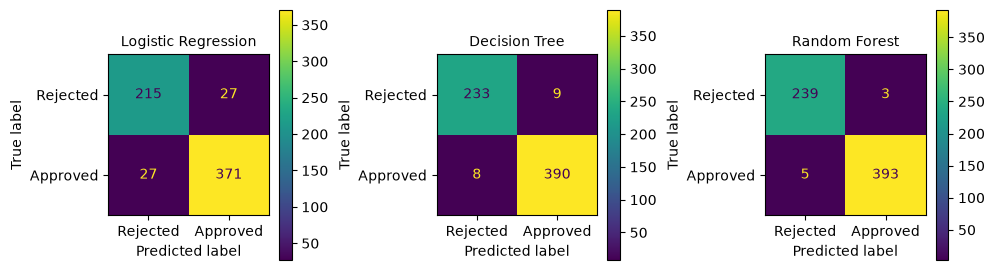

In [140]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, (name, pipeline) in zip(axes, results.items()):
    y_pred = pipeline.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        display_labels=["Rejected", "Approved"],
        ax=ax
    )

    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

**Observation:** The confusion matrices show that Random Forest makes the fewest validation errors, with 8 incorrect predictions compared with 17 for the Decision Tree and 54 for Logistic Regression. This suggests that the tree-based models are performing better at distinguishing approved and rejected loan applications at the baseline stage.

### 7.2 Classification Reports

The classification report provides precision, recall, and F1-score for each loan-status class.

This gives more detail about how well each model identifies both rejected and approved applications.

In [141]:
from sklearn.metrics import classification_report

for name, pipeline in results.items():
    y_pred = pipeline.predict(X_val)

    print(f"\n{name}")
    print(classification_report(
        y_val,
        y_pred,
        target_names=["Rejected", "Approved"]
    ))



Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.89      0.89      0.89       242
    Approved       0.93      0.93      0.93       398

    accuracy                           0.92       640
   macro avg       0.91      0.91      0.91       640
weighted avg       0.92      0.92      0.92       640


Decision Tree
              precision    recall  f1-score   support

    Rejected       0.97      0.96      0.96       242
    Approved       0.98      0.98      0.98       398

    accuracy                           0.97       640
   macro avg       0.97      0.97      0.97       640
weighted avg       0.97      0.97      0.97       640


Random Forest
              precision    recall  f1-score   support

    Rejected       0.98      0.99      0.98       242
    Approved       0.99      0.99      0.99       398

    accuracy                           0.99       640
   macro avg       0.99      0.99      0.99       640
weighted avg       0.99

In [142]:
rf_pred = results["Random Forest"].predict(X_val)

print(classification_report(
    y_val,
    rf_pred,
    target_names=["Rejected", "Approved"]
))

              precision    recall  f1-score   support

    Rejected       0.98      0.99      0.98       242
    Approved       0.99      0.99      0.99       398

    accuracy                           0.99       640
   macro avg       0.99      0.99      0.99       640
weighted avg       0.99      0.99      0.99       640



### 7.3 Error Analysis Summary

The classification reports provide a more detailed view of how each baseline model performs for both loan-status classes.

**Logistic Regression:**  
The model achieves an overall accuracy of **0.92**, with an F1-score of **0.89** for Rejected applications and **0.93** for Approved applications. This indicates that Logistic Regression performs reasonably well but has more difficulty distinguishing between the two loan outcomes compared with the tree-based models.

**Decision Tree:**  
The Decision Tree improves to an overall accuracy of **0.97**. Its F1-scores are **0.96** for Rejected applications and **0.98** for Approved applications. This shows that the model makes substantially fewer classification errors than Logistic Regression and performs well for both classes.

**Random Forest:**  
The Random Forest achieves the strongest baseline performance, with an overall accuracy and F1-score of **0.99**. Its performance is also balanced across the two classes, indicating that it can identify both Rejected and Approved applications with very few errors.

The confusion matrices support these results. Random Forest produced only **8 incorrect predictions**, compared with **17** for the Decision Tree and **54** for Logistic Regression.

**Conclusion:**  
The tree-based models currently perform better than Logistic Regression for this loan approval problem. Random Forest provides the strongest baseline results, while Decision Tree also performs well. However, these are still baseline models. Hyperparameter tuning will be used in the next step to determine whether their performance can be improved further.

The **test set remains untouched** at this stage and will only be used for the final evaluation of the selected model.

### Step 8: Hyperparameter Tuning

The baseline models use their default hyperparameters. However, different parameter settings may improve their performance.

GridSearchCV will test a predefined set of hyperparameter combinations and evaluate them using **5-fold cross-validation** on the training data.

F1-score is used as the scoring metric because it considers both precision and recall. The validation set remains separate so that it can be used to evaluate the tuned models after training.

The test set will remain untouched until the final evaluation.

In [143]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter combinations for each model
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
    },
    
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10]
    },
    
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    }
}

# Store the tuned models
tuned_models = {}

# Tune each model
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=1
    )

    grid.fit(X_train, y_train)

    tuned_models[name] = grid

    print(f"{name} tuning completed.")
    print(f"Best parameters: {grid.best_params_}")
    print(f"Best CV F1 Score: {grid.best_score_:.2f}")
    print()

print("Hyperparameter tuning completed successfully.")

Logistic Regression tuning completed.
Best parameters: {'model__C': 0.1}
Best CV F1 Score: 0.93

Decision Tree tuning completed.
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2}
Best CV F1 Score: 0.98

Random Forest tuning completed.
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1 Score: 0.98

Hyperparameter tuning completed successfully.


In [144]:
tuned_results = []

for name, grid in tuned_models.items():
    y_pred = grid.predict(X_val)

    tuned_results.append({
        "Model": name,
        "CV F1": grid.best_score_,
        "Validation Accuracy": accuracy_score(y_val, y_pred),
        "Validation Precision": precision_score(y_val, y_pred),
        "Validation Recall": recall_score(y_val, y_pred),
        "Validation F1": f1_score(y_val, y_pred)
    })

tuned_df = pd.DataFrame(tuned_results)

display(tuned_df.round(2))

,Model,CV F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Logistic Regression,0.93,0.92,0.93,0.94,0.93
1,Decision Tree,0.98,0.97,0.98,0.98,0.98
2,Random Forest,0.98,0.98,0.99,0.98,0.99


### 8.6 Tuned Model Comparison

The tuned models were evaluated on the validation set and compared using the same metrics as the baseline models.

Logistic Regression achieved a validation F1-score of **0.93**, while the Decision Tree achieved **0.98**. Random Forest achieved the highest validation F1-score of **0.99**, with **0.98 accuracy**, **0.99 precision**, and **0.98 recall**.

The results show that Random Forest provides the strongest validation performance among the three tuned models. It also maintains a good balance between precision and recall, with only a small difference between the two.

Therefore, **Random Forest will be selected as the final candidate model** and evaluated once on the untouched test set in Step 9.

The test set has not been used during model selection, so it provides an unbiased final estimate of how the selected model performs on unseen data.

## Step 9 — Final Evaluation

### 9.1 Select the Final Model

Based on the validation results, Random Forest achieved the highest validation F1-score of 0.99.

It will therefore be selected as the final candidate model. The test set will now be used for the first time to measure how well this model performs on completely unseen data.

In [145]:
best_model_name = tuned_df.loc[
    tuned_df["Validation F1"].idxmax(),
    "Model"
]

best_model = tuned_models[best_model_name]

print("Final Model:", best_model_name)

Final Model: Random Forest


### 9.2 Final Test Evaluation

The selected Random Forest model is now evaluated on the untouched test set.

Accuracy, precision, recall, F1-score, and ROC-AUC are reported to provide a complete assessment of the model's performance on unseen loan applications.

In [146]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("FINAL TEST RESULTS")
print(f"Accuracy : {test_accuracy:.2f}")
print(f"Precision: {test_precision:.2f}")
print(f"Recall   : {test_recall:.2f}")
print(f"F1 Score : {test_f1:.2f}")
print(f"ROC-AUC  : {test_auc:.2f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Rejected", "Approved"]
))

FINAL TEST RESULTS
Accuracy : 0.98
Precision: 0.99
Recall   : 0.98
F1 Score : 0.98
ROC-AUC  : 1.00

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.97      0.98      0.98       242
    Approved       0.99      0.98      0.98       399

    accuracy                           0.98       641
   macro avg       0.98      0.98      0.98       641
weighted avg       0.98      0.98      0.98       641



#### 9.2 Validation vs Test

Comparing validation and test performance helps check whether the model generalizes well to unseen data. Similar results suggest that the model has not strongly overfit the validation set.

In [147]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Validation": [
        accuracy_score(y_val, best_model.predict(X_val)),
        precision_score(y_val, best_model.predict(X_val)),
        recall_score(y_val, best_model.predict(X_val)),
        f1_score(y_val, best_model.predict(X_val)),
        roc_auc_score(y_val, best_model.predict_proba(X_val)[:, 1])
    ],
    "Test": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

display(comparison.round(3))

,Metric,Validation,Test
0,Accuracy,0.98,0.98
1,Precision,0.99,0.99
2,Recall,0.98,0.98
3,F1,0.99,0.98
4,ROC-AUC,1.00,1.00


### 9.4 Final Confusion Matrix

The confusion matrix shows how the final Random Forest model classified the test applications.

It separates correct predictions from incorrect predictions and allows us to see whether the model makes more false approvals or false rejections.

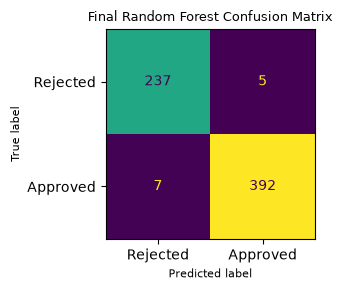

In [148]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(3.5, 3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Rejected", "Approved"],
    ax=ax,
    colorbar=False
)

ax.set_title("Final Random Forest Confusion Matrix", fontsize=9)
ax.set_xlabel("Predicted label", fontsize=8)
ax.set_ylabel("True label", fontsize=8)

plt.tight_layout()
plt.show()

### 9.5 Final Model Summary

The Random Forest model was selected as the final model because it achieved the strongest validation performance among the three models.

After hyperparameter tuning, the model achieved a validation F1-score of **0.99** and a final test F1-score of **0.98**.

The small difference between validation and test performance suggests that the model generalizes well to unseen loan applications.

Overall, the final model provides strong performance in distinguishing between approved and rejected applications while maintaining a good balance between precision and recall.

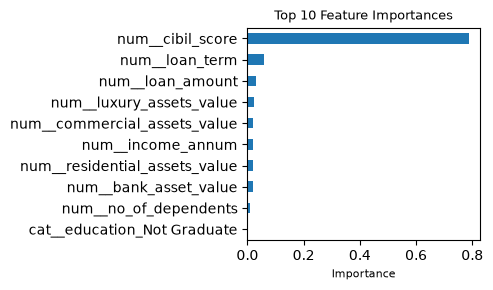

In [149]:
best_estimator = best_model.best_estimator_

model_step = best_estimator.named_steps["model"]
feature_names = best_estimator.named_steps["preprocessor"].get_feature_names_out()

feature_importance = pd.Series(
    model_step.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

plt.figure(figsize=(5, 3))

feature_importance.sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances", fontsize=9)
plt.xlabel("Importance", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** The feature importance plot shows which variables contributed most to the Random Forest's predictions. Features with higher importance had a greater influence on the model's classification decisions.

This provides additional insight into the factors that are most useful for predicting loan approval, while the importance values should not be interpreted as proof of causation.

## Final Project Conclusion

This project developed a supervised machine learning model to predict whether a loan application would be **Approved** or **Rejected**.

The data was cleaned and validated before modelling. During EDA, CIBIL score, income, loan amount, education, and self-employment were examined because of their relevance to loan approval. The correlation analysis also identified redundant financial information, leading to the removal of `luxury_assets_value`.

Three classification models were evaluated: Logistic Regression, Decision Tree, and Random Forest. Hyperparameter tuning was then performed using 5-fold cross-validation with F1-score as the scoring metric.

Random Forest was selected as the final model because it achieved the strongest validation performance. On the previously unseen test set, it achieved **0.98 accuracy, 0.99 precision, 0.98 recall, 0.98 F1-score, and 1.00 ROC-AUC**.

Overall, the final model demonstrated strong performance in distinguishing between approved and rejected loan applications and generalized well to the unseen test data.

In [150]:
import joblib
import json

joblib.dump(best_model, "final_model.pkl")

final_config = {
    "model": best_model_name,
    "best_params": best_model.best_params_,
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "test_auc": float(test_auc)
}

with open("final_config.json", "w") as f:
    json.dump(final_config, f, indent=2)

print("Final model and configuration saved.")

Final model and configuration saved.
